# EfficientNet-B0 Model — Multi-Run Evaluation (Mean ± SD)

This notebook trains the EfficientNet-B0 model **multiple independent times** (different random seeds each time,
including a fresh train/val/test split each run) so that classification metrics can be reported as
**mean ± SD** for both the internal (held-out test) set and the external validation set, as is standard
practice when reporting results in a paper/report.

Each full run (data split → Stage 1 training → Stage 2 fine-tuning → internal test eval → external eval)
is **cached to disk** as soon as it finishes. If the kernel/notebook is interrupted, re-running the "Execute
all runs" cell will skip every run that already has a cache file and only continue with the runs that are
still missing — so you never have to redo completed runs.

## Import Libraries and Set Configurations

In [1]:
# Import the relevant libraries
from utils.seed_utils import *
from utils.data_utils import *
from utils.training_evaluation_utils import *
from utils.external_validation_utils import *
from utils.cache_utils import *
from utils.results_utils import *
from utils.experiment_runner import (run_single_experiment as shared_run_single_experiment)

import os
import json
import copy
import numpy as np
import pandas as pd
import torch.optim as optim
import torch
import torch.nn as nn
from functools import partial

from sklearn.utils.class_weight import compute_class_weight
from torchvision import models
from torchvision.models import EfficientNet_B0_Weights

import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader

In [2]:
# List the configurations
DATA_DIR = "../data/EBHI-SEG"

BATCH_SIZE = 32
NUM_WORKERS = 0
IMAGE_SIZE = 224
NUM_EPOCHS_STAGE1 = 15
NUM_EPOCHS_STAGE2 = 25

LR_STAGE1 = 1e-3
LR_STAGE2 = 3e-5

WEIGHT_DECAY = 1e-4
PATIENCE = 5
LABEL_SMOOTHING = 0.05

## Multi-Run Configuration

In [3]:
# Multi-run configuration
SPLIT_SEED = 42
RUN_SEEDS = [42, 123, 2024, 3407, 9999, 7, 77, 314, 2025, 8888]
N_RUNS = len(RUN_SEEDS)
CACHE_DIR = "outputs/efficientnetb0/run_cache"
RESULTS_DIR = "outputs/efficientnetb0"
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

SAVE_MODEL_PER_RUN = True
if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print("Using device:", DEVICE)
print(f"Planned runs: {N_RUNS} (seeds {RUN_SEEDS})")

Using device: mps
Planned runs: 10 (seeds [42, 123, 2024, 3407, 9999, 7, 77, 314, 2025, 8888])


## Caching Functions

In [4]:
# Configure shared caching functions for this architecture
run_cache_path = partial(run_cache_path, cache_dir=CACHE_DIR)
run_model_path = partial(run_model_path, cache_dir=CACHE_DIR)
load_cached_run = partial(load_cached_run, cache_dir=CACHE_DIR)
save_run_cache = partial(save_run_cache, cache_dir=CACHE_DIR)

## Building the EfficientNet-B0 Model

In [5]:
def build_efficientnet_b0(num_classes):
    weights = EfficientNet_B0_Weights.DEFAULT
    model = models.efficientnet_b0(weights=weights)
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(0.4),
        nn.Linear(in_features, 512),
        nn.BatchNorm1d(512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, 128),
        nn.BatchNorm1d(128),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(128, num_classes)
    )
    return model

# Function to freeze backbone
def freeze_backbone(model):
    for param in model.parameters():
        param.requires_grad = False
    for param in model.classifier.parameters():
        param.requires_grad = True


# Function to unfreeze for fine-tuning
def unfreeze_for_finetuning(model):
    for param in model.parameters():
        param.requires_grad = False
    for param in model.classifier.parameters():
        param.requires_grad = True
    # Fine-tune last EfficientNet blocks
    for param in model.features[6:].parameters():
        param.requires_grad = True

## External Validation Configuration

In [6]:
EXTERNAL_DIR = "../data/lung_colon_image_set/Test Set"
EXTERNAL_IMAGE_SIZE = 224
EXTERNAL_BATCH_SIZE = 16
EXTERNAL_NUM_WORKERS = 0

external_class_names = [
    "Adenocarcinoma",
    "High-grade IN",
    "Low-grade IN",
    "Normal",
    "Polyp",
    "Serrated adenoma"
]
external_class_to_index = {cls: i for i, cls in enumerate(external_class_names)}

external_label_map = {
    "colon_aca": "Adenocarcinoma",
    "colon_n": "Normal"
}

external_labels = [external_class_to_index[c] for c in external_label_map.values()]
external_target_names = list(external_label_map.values())

## Single-Run Experiment

In [7]:
def run_single_experiment(run_idx, seed):
    return shared_run_single_experiment(
        run_idx=run_idx,
        seed=seed,

        # Architecture-specific configuration
        model_name="EfficientNet-B0",
        build_model=build_efficientnet_b0,
        freeze_backbone=freeze_backbone,
        unfreeze_for_finetuning=unfreeze_for_finetuning,

        # Dataset and preprocessing
        data_dir=DATA_DIR,
        split_seed=SPLIT_SEED,
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS,
        device=DEVICE,

        # Training configuration
        label_smoothing=LABEL_SMOOTHING,
        lr_stage1=LR_STAGE1,
        lr_stage2=LR_STAGE2,
        weight_decay=WEIGHT_DECAY,
        num_epochs_stage1=NUM_EPOCHS_STAGE1,
        num_epochs_stage2=NUM_EPOCHS_STAGE2,
        patience=PATIENCE,

        # External validation
        external_dir=EXTERNAL_DIR,
        external_label_map=external_label_map,
        external_class_to_index=external_class_to_index,
        external_image_size=EXTERNAL_IMAGE_SIZE,
        external_batch_size=EXTERNAL_BATCH_SIZE,
        external_num_workers=EXTERNAL_NUM_WORKERS,
        external_labels=external_labels,
        external_target_names=external_target_names,
        external_class_names=external_class_names,

        # Checkpoint saving
        save_model_per_run=SAVE_MODEL_PER_RUN,
        model_path_fn=run_model_path,
    )


## Run a Single Experiment (with caching)

In [8]:
# Configure the shared run-or-load function
run_or_load = partial(
    run_or_load,
    cache_dir=CACHE_DIR,
    run_single_experiment=run_single_experiment
)

## Execute All Runs

Runs (or loads from cache) each of the `N_RUNS` repetitions in sequence.
train.

In [9]:
all_run_results = []

for i, seed in enumerate(RUN_SEEDS):
    result = run_or_load(i, seed)
    all_run_results.append(result)

print(f"\nCollected {len(all_run_results)} / {N_RUNS} runs.")

[cache] Run 0 (seed=42) already cached — skipping training.
[cache] Run 1 (seed=123) already cached — skipping training.
[cache] Run 2 (seed=2024) already cached — skipping training.
[cache] Run 3 (seed=3407) already cached — skipping training.
[cache] Run 4 (seed=9999) already cached — skipping training.
[cache] Run 5 (seed=7) already cached — skipping training.
[cache] Run 6 (seed=77) already cached — skipping training.
[cache] Run 7 (seed=314) already cached — skipping training.
[cache] Run 8 (seed=2025) already cached — skipping training.
[cache] Run 9 (seed=8888) already cached — skipping training.

Collected 10 / 10 runs.


## Aggregate Results: Mean ± SD

In [10]:
sections = {
    "Internal Test (Normal, no TTA)": "internal_normal",
    "Internal Test (TTA)": "internal_tta",
    "External Validation (Normal, no TTA)": "external_normal",
    "External Validation (TTA)": "external_tta",
}

summary_tables = {}

for title, key in sections.items():
    df = aggregate_section(all_run_results, key)
    summary_tables[key] = df

    print("\n" + "=" * 70)
    print(title, f"(n={len(all_run_results)} runs)")
    print("=" * 70)

    if df.empty:
        print("No numeric metrics found for this section.")
    else:
        print(df[["metric", "mean_pm_sd"]].to_string(index=False))


Internal Test (Normal, no TTA) (n=10 runs)
          metric      mean_pm_sd
        accuracy 0.8537 ± 0.0194
        f1_macro 0.7627 ± 0.0334
            loss 0.9640 ± 0.0377
   macro_roc_auc 0.9688 ± 0.0061
 precision_macro 0.7451 ± 0.0332
    recall_macro 0.7909 ± 0.0359
weighted_roc_auc 0.9765 ± 0.0042

Internal Test (TTA) (n=10 runs)
          metric      mean_pm_sd
        accuracy 0.8603 ± 0.0162
        f1_macro 0.7830 ± 0.0212
            loss 1.0613 ± 0.0240
   macro_roc_auc 0.9795 ± 0.0032
 precision_macro 0.7650 ± 0.0218
    recall_macro 0.8120 ± 0.0214
weighted_roc_auc 0.9826 ± 0.0025

External Validation (Normal, no TTA) (n=10 runs)
   metric      mean_pm_sd
 accuracy 0.4048 ± 0.0467
 macro_f1 0.5158 ± 0.0521
precision 0.7390 ± 0.0345
   recall 0.4048 ± 0.0467

External Validation (TTA) (n=10 runs)
   metric      mean_pm_sd
 accuracy 0.4375 ± 0.0502
 macro_f1 0.5474 ± 0.0520
precision 0.7530 ± 0.0344
   recall 0.4375 ± 0.0502


## Save Aggregated Summary and Per-Run Table
- `efficientnetb0_multirun_summary.json`: mean/SD for every metric, per section
- `efficientnetb0_multirun_per_run.csv`: the raw per-run scalar metrics (one row per run) for full transparency
- Each individual run's full result remains available under `outputs/efficientnetb0/run_cache/`

In [11]:
# Save mean +/- SD summary 
summary_json = {
    title: df.to_dict(orient="records")
    for title, df in zip(sections.keys(), summary_tables.values())
}
summary_json["n_runs"] = len(all_run_results)
summary_json["seeds"] = [r["seed"] for r in all_run_results]

summary_path = os.path.join(RESULTS_DIR, "efficientnetb0_multirun_summary.json")
with open(summary_path, "w") as f:
    json.dump(summary_json, f, indent=2)
print("Saved aggregated summary to:", summary_path)

# Save a flat per-run CSV for transparency/re-analysis 
per_run_rows = []
for r in all_run_results:
    row = {"run_idx": r["run_idx"], "seed": r["seed"]}
    for section_key in ["internal_normal", "internal_tta", "external_normal", "external_tta"]:
        if section_key in r:
            for k, v in flatten_numeric(r[section_key]).items():
                row[f"{section_key}.{k}"] = v
    per_run_rows.append(row)

per_run_df = pd.DataFrame(per_run_rows)
per_run_csv_path = os.path.join(RESULTS_DIR, "efficientnetb0_multirun_per_run.csv")
per_run_df.to_csv(per_run_csv_path, index=False)
print("Saved per-run metrics to:", per_run_csv_path)

per_run_df

Saved aggregated summary to: outputs/efficientnetb0/efficientnetb0_multirun_summary.json
Saved per-run metrics to: outputs/efficientnetb0/efficientnetb0_multirun_per_run.csv


,run_idx,seed,internal_normal.loss,internal_normal.accuracy,internal_normal.precision_macro,internal_normal.recall_macro,internal_normal.f1_macro,internal_normal.macro_roc_auc,internal_normal.weighted_roc_auc,internal_tta.loss,...,internal_tta.macro_roc_auc,internal_tta.weighted_roc_auc,external_normal.accuracy,external_normal.precision,external_normal.recall,external_normal.macro_f1,external_tta.accuracy,external_tta.precision,external_tta.recall,external_tta.macro_f1
0,0,42,0.977886,0.841791,0.739670,0.759842,0.748604,0.969360,0.975408,1.071972,...,0.978536,0.981113,0.315,0.701415,0.315,0.415151,0.330,0.699572,0.330,0.435322
1,1,123,0.926532,0.868657,0.769313,0.829253,0.793895,0.972729,0.980182,1.025138,...,0.983037,0.985162,0.405,0.755864,0.405,0.517040,0.430,0.768310,0.430,0.532803
2,2,2024,1.023595,0.814925,0.674227,0.724326,0.693603,0.961356,0.970226,1.105771,...,0.974835,0.979444,0.463,0.762012,0.463,0.575009,0.505,0.776044,0.505,0.611680
3,3,3407,1.013431,0.853731,0.736686,0.801523,0.760261,0.957549,0.970058,1.076355,...,0.973919,0.979271,0.339,0.685460,0.339,0.442603,0.398,0.714413,0.398,0.506379
4,4,9999,0.926683,0.850746,0.739044,0.826907,0.772827,0.975661,0.979574,1.057213,...,0.982806,0.984001,0.438,0.753645,0.438,0.552980,0.486,0.773009,0.486,0.596735
5,5,7,0.940398,0.877612,0.780530,0.824459,0.799257,0.973151,0.981098,1.030515,...,0.982149,0.985991,0.451,0.798732,0.451,0.576347,0.475,0.809488,0.475,0.598132
6,6,77,0.955986,0.859701,0.756734,0.784509,0.768087,0.972520,0.978756,1.049311,...,0.981017,0.984238,0.398,0.702316,0.398,0.505509,0.423,0.711961,0.423,0.530376
7,7,314,0.913463,0.877612,0.793201,0.816553,0.802055,0.974353,0.980978,1.049446,...,0.981832,0.984724,0.403,0.759802,0.403,0.526536,0.420,0.768303,0.420,0.542984
8,8,2025,0.978973,0.856716,0.735353,0.788677,0.757799,0.964589,0.975055,1.070954,...,0.977933,0.980991,0.429,0.740126,0.429,0.527762,0.463,0.753587,0.463,0.567221
9,9,8888,0.983395,0.835821,0.726321,0.752585,0.730463,0.966791,0.973518,1.076580,...,0.979316,0.981241,0.407,0.730471,0.407,0.518967,0.445,0.755401,0.445,0.552070


## Confusion Matrix for a Single Reference Run

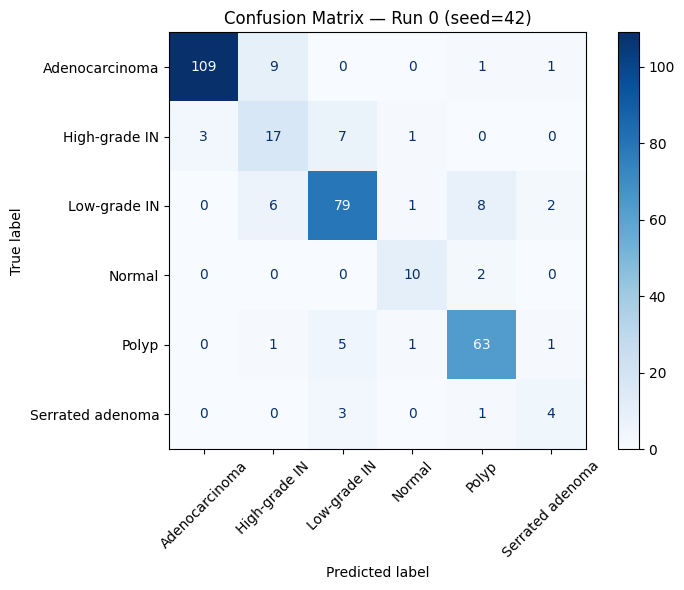

In [12]:
reference_run = all_run_results[0]

cm_ref = np.array(reference_run["internal_normal_extra"]["confusion_matrix"])
display = ConfusionMatrixDisplay(
    confusion_matrix=cm_ref,
    display_labels=reference_run["class_names"]
)
fig, ax = plt.subplots(figsize=(8, 6))
display.plot(cmap="Blues", ax=ax, values_format="d")
plt.title(f"Confusion Matrix — Run {reference_run['run_idx']} (seed={reference_run['seed']})")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()